# LA28 Host-City Analysis — Athlete Load by Venue Zone

**SportsFanatics | Data Analysis — 2028 Olympic Planning**

This notebook reconstructs the recommendation for the **host city of Los Angeles**:
a data-driven map of where athlete volume concentrates across LA28's distributed
venue plan, and a zone-weighted resource-allocation recommendation that follows
from it.

### The question
LA28 is the most geographically *distributed* Summer Games in modern history —
venues are split into "zones" stretching from Downtown LA to Long Beach, Carson,
the San Fernando Valley, and beyond. The hardest operational problem is therefore
not *which sport* is biggest, but **which geographic zones absorb the most athlete
load simultaneously**, and how transit, housing, medical, and security resources
should be pre-positioned to match.

### Method (3 steps)
1. **Athlete load per sport** — count unique athletes per sport at a reference
   Games (Rio 2016, consistent with the rest of our analysis).
2. **Map each sport → its official LA28 zone** — using LA28's published venue plan
   (March 2026 venue map).
3. **Aggregate athlete load by zone** → a Zone Load Index that drives the
   resource recommendation.

### Scope note (stated up front for the judges)
LA28 adds five sports absent from the historical record — cricket, flag football,
lacrosse, squash, and baseball/softball. This analysis models the **31 returning
sports**, which account for the overwhelming majority of athlete volume. The five
new sports are handled as a flagged incremental load (Pomona, Dodger Stadium, and
the Oklahoma City subsite) in the accompanying judge supplement, not in this
core model.


## 1 · Load the data

The provided Kaggle datasets: `athlete_events.csv` (one row per athlete-event,
1896–2016) and `noc_regions.csv` (NOC → country mapping).

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option('display.max_rows', 40)

# Load the provided datasets
athletes = pd.read_csv('athlete_events.csv')
noc = pd.read_csv('noc_regions.csv')

print(f"athlete_events: {athletes.shape[0]:,} rows  ×  {athletes.shape[1]} cols")
print(f"noc_regions:    {noc.shape[0]:,} rows")
athletes.head(3)

athlete_events: 271,116 rows  ×  15 cols
noc_regions:    230 rows


,ID,Name,Sex,Age,Height,Weight,Team,NOC,Games,Year,Season,City,Sport,Event,Medal
0,1,A Dijiang,M,24.0,180.0,80.0,China,CHN,1992 Summer,1992,Summer,Barcelona,Basketball,Basketball Men's Basketball,NaN
1,2,A Lamusi,M,23.0,170.0,60.0,China,CHN,2012 Summer,2012,Summer,London,Judo,Judo Men's Extra-Lightweight,NaN
2,3,Gunnar Nielsen Aaby,M,24.0,NaN,NaN,Denmark,DEN,1920 Summer,1920,Summer,Antwerpen,Football,Football Men's Football,NaN


## 2 · Filter to the reference Games (Rio 2016, Summer)

We use **Rio 2016** as the reference Games — the most recent Summer Olympics in
the dataset, and the same reference used throughout our medal and clustering
analysis. We confirm the athlete and sport counts before proceeding.

In [ ]:
rio = athletes[(athletes['Year'] == 2016) & (athletes['Season'] == 'Summer')].copy()

print(f"Rio 2016 athlete-event rows : {len(rio):,}")
print(f"Unique athletes (by ID)     : {rio['ID'].nunique():,}")
print(f"Unique sports               : {rio['Sport'].nunique()}")


Rio 2016 athlete-event rows : 13,688
Unique athletes (by ID)     : 11,179
Unique sports               : 34


## 3 · Athlete load per sport

We count **unique athletes per sport** (`ID.nunique()`), not raw event rows, so an
athlete entered in multiple events within a sport is counted once. At Rio 2016 no
athlete competed in more than one sport, so these per-sport counts sum exactly to
the 11,179 total — a useful internal check.

In [ ]:
sport_load = (rio.groupby('Sport')['ID'].nunique()
                 .sort_values(ascending=False)
                 .rename('athletes'))

# Internal check: per-sport counts should sum to total unique athletes
assert sport_load.sum() == rio['ID'].nunique(), "athletes double-counted across sports"
print(f"Sum of per-sport loads = {sport_load.sum():,}  (matches unique athletes)\n")
sport_load.to_frame()

Sum of per-sport loads = 11,179  (matches unique athletes)



,athletes
Sport,
Athletics,2269
Swimming,942
Rowing,546
Cycling,513
Football,473
Hockey,390
Shooting,390
Judo,389
Sailing,380


## 4 · Map each sport to its official LA28 zone

LA28 groups venues into geographic **zones** ("sports parks"). We map every sport
in the dataset to the zone hosting it under LA28's published plan.

**Two data nuances handled explicitly:**

- **Aquatics is split across zones at LA28.** The dataset separates `Swimming`,
  `Diving`, `Synchronized Swimming`, and `Water Polo` — and LA28 happens to place
  these in *different* zones: swimming at SoFi/2028 Stadium (Inglewood), diving at
  the Rose Bowl Aquatics Center (Pasadena), and artistic swimming + water polo in
  a temporary pool at the Long Beach Convention Center. The split mapping is
  therefore correct, not an artifact.
- **Gymnastics** is likewise split (`Gymnastics`, `Rhythmic Gymnastics`,
  `Trampolining`) — all hosted in the Downtown/Exposition Park cluster.

Where the dataset uses a single label for a sport LA28 spreads across sub-venues
(e.g. `Cycling` covers track + road + BMX), we assign the zone of the **primary /
highest-athlete** sub-venue. This is documented per sport below.

In [ ]:
# Sport -> LA28 zone (official venue plan, March 2026 map)
zone_map = {
    # --- Downtown / Exposition Park cluster ---
    'Athletics':            'Downtown/Exposition Park',  # LA Memorial Coliseum
    'Gymnastics':           'Downtown/Exposition Park',  # DTLA Arena (artistic)
    'Trampolining':         'Downtown/Exposition Park',  # DTLA Arena
    'Rhythmic Gymnastics':  'Downtown/Exposition Park',  # near gymnastics venues
    'Boxing':               'Downtown/Exposition Park',  # Peacock Theater / Crypto finals
    'Weightlifting':        'Downtown/Exposition Park',  # Peacock Theater
    'Fencing':              'Downtown/Exposition Park',  # LA Convention Center
    'Judo':                 'Downtown/Exposition Park',  # LA Convention Center
    'Table Tennis':         'Downtown/Exposition Park',  # LA Convention Center
    'Taekwondo':            'Downtown/Exposition Park',  # LA Convention Center
    'Wrestling':            'Downtown/Exposition Park',  # LA Convention Center
    'Badminton':            'Downtown/Exposition Park',  # Galen Center (USC / Expo Park)

    # --- Long Beach cluster (11 sports IRL; 8 present in 2016 data) ---
    'Synchronized Swimming':'Long Beach',  # Convention Center temp pool (artistic swimming)
    'Water Polo':           'Long Beach',  # Convention Center temp pool
    'Handball':             'Long Beach',  # Long Beach Arena
    'Rowing':               'Long Beach',  # Marine Stadium
    'Canoeing':             'Long Beach',  # Marine Stadium (sprint)
    'Sailing':              'Long Beach',  # Belmont Shore
    'Beach Volleyball':     'Long Beach',  # Alamitos Beach
    'Shooting':             'Long Beach',  # Target shooting, LB Convention Center

    # --- Carson cluster (CSU Dominguez Hills) ---
    'Cycling':              'Carson',  # Velodrome (track) - primary cycling venue
    'Hockey':               'Carson',  # Carson Field (field hockey)
    'Rugby Sevens':         'Carson',  # Carson Stadium
    'Archery':              'Carson',  # Carson Stadium
    'Tennis':               'Carson',  # Carson Courts

    # --- Inglewood ---
    'Swimming':             'Inglewood',  # SoFi / 2028 Stadium
    'Basketball':           'Inglewood',  # Intuit Dome (5x5)

    # --- Pasadena ---
    'Diving':               'Pasadena',  # Rose Bowl Aquatics Center
    'Football':             'Pasadena',  # Rose Bowl (final / primary venue)

    # --- Single-venue outlying zones ---
    'Volleyball':           'Anaheim',             # Honda Center
    'Equestrianism':        'Arcadia',             # Santa Anita Park
    'Golf':                 'Pacific Palisades',   # Riviera Country Club
    'Triathlon':            'Venice',              # Venice Beach
    'Modern Pentathlon':    'San Fernando Valley', # Sepulveda Basin
}

# Validate: every sport in the data has a zone
unmapped = set(rio['Sport'].unique()) - set(zone_map)
assert not unmapped, f"Unmapped sports: {unmapped}"
print(f"All {rio['Sport'].nunique()} sports mapped to a zone. ✓")

All 34 sports mapped to a zone. ✓


## 5 · Aggregate athlete load by zone → the bottleneck map

This is the core result. We attach the zone to each athlete row and aggregate
unique athletes per zone.

In [ ]:
rio['Zone'] = rio['Sport'].map(zone_map)

total = rio['ID'].nunique()
zone_load = (rio.groupby('Zone')['ID'].nunique()
                .sort_values(ascending=False)
                .rename('athletes'))
zone_sports = rio.groupby('Zone')['Sport'].nunique().rename('n_sports')

zone_summary = pd.concat([zone_load, zone_sports], axis=1)
zone_summary['share_%'] = (zone_summary['athletes'] / total * 100).round(1)
# Zone Load Index: heaviest zone = 100
zone_summary['load_index'] = (zone_summary['athletes'] /
                              zone_summary['athletes'].max() * 100).round(1)

print(f"Top-3 zones carry "
      f"{zone_summary['share_%'].head(3).sum():.0f}% of all athlete load\n")
zone_summary

Top-3 zones carry 77% of all athlete load



,athletes,n_sports,share_%,load_index
Zone,,,,
Downtown/Exposition Park,4581,12,41.0,100.0
Long Beach,2455,8,22.0,53.6
Carson,1526,5,13.7,33.3
Inglewood,1223,2,10.9,26.7
Pasadena,609,2,5.4,13.3
Anaheim,283,1,2.5,6.2
Arcadia,200,1,1.8,4.4
Pacific Palisades,120,1,1.1,2.6
Venice,110,1,1.0,2.4


**Reading the result.** Three zones — Downtown/Exposition Park, Long Beach, and
Carson — absorb roughly **77% of all athlete load**. Downtown alone carries ~41%
across 12 sports. Critically, the heaviest zones are *not* the most famous venues:
Inglewood (SoFi swimming + Intuit basketball) sits at only ~11%. Resource planning
keyed to marquee venues would mis-allocate against the real load.

## 6 · The Downtown pressure cluster (supporting detail)

Why Downtown's 41% is an operational concern rather than just a large number: the
load is **stacked in two adjacent venue complexes**.

- The **LA Convention Center** hosts five combat/precision sports in one building.
- The **LA Memorial Coliseum** hosts athletics — the single largest contingent.

Both sit in the same zone, compounding transit and athlete-shuttle demand on
overlapping days.

In [ ]:
convention_center = ['Fencing', 'Judo', 'Table Tennis', 'Taekwondo', 'Wrestling']
cc_load = rio[rio['Sport'].isin(convention_center)]['ID'].nunique()
coliseum_load = rio[rio['Sport'] == 'Athletics']['ID'].nunique()

print("LA Convention Center — 5 sports in one building:")
for s in convention_center:
    print(f"   {s:<14}{rio[rio['Sport']==s]['ID'].nunique():>5}")
print(f"   {'-'*19}")
print(f"   {'TOTAL':<14}{cc_load:>5} athletes in one venue complex")
print(f"\nLA Memorial Coliseum (Athletics): {coliseum_load:,} athletes")
print(f"\nBoth complexes sit in the Downtown/Exposition Park zone.")

LA Convention Center — 5 sports in one building:
   Fencing         245
   Judo            389
   Table Tennis    172
   Taekwondo       126
   Wrestling       346
   -------------------
   TOTAL          1278 athletes in one venue complex

LA Memorial Coliseum (Athletics): 2,269 athletes

Both complexes sit in the Downtown/Exposition Park zone.


## 7 · Robustness — is the concentration a Rio fluke?

A natural challenge: *single-Games athlete counts are noisy.* We test whether the
zone concentration is **structural** by recomputing the zone shares for the three
most recent Summer Games (2008, 2012, 2016) under the identical mapping.

In [ ]:
def zone_shares(year):
    g = athletes[(athletes['Year'] == year) &
                 (athletes['Season'] == 'Summer')].copy()
    g['Zone'] = g['Sport'].map(zone_map)
    g = g.dropna(subset=['Zone'])          # drop sports not held that year
    z = g.groupby('Zone')['ID'].nunique()
    return (z / z.sum() * 100)

robust = pd.DataFrame({yr: zone_shares(yr) for yr in [2008, 2012, 2016]})
robust = robust.loc[zone_load.index].round(1)          # order by 2016 ranking
robust.columns = [f"{c} %" for c in robust.columns]

top3_by_year = {yr: zone_shares(yr).sort_values(ascending=False)
                          .head(3).sum() for yr in [2008, 2012, 2016]}
print("Top-3 zone share by Games:")
for yr, s in top3_by_year.items():
    print(f"   {yr}:  {s:.1f}%")
print()
robust

Top-3 zone share by Games:
   2008:  76.8%
   2012:  76.5%
   2016:  76.6%



,2008 %,2012 %,2016 %
Zone,,,
Downtown/Exposition Park,41.1,41.6,41.0
Long Beach,23.3,23.3,22.0
Carson,11.3,11.4,13.7
Inglewood,12.4,11.6,10.9
Pasadena,5.8,5.7,5.4
Anaheim,2.7,2.7,2.5
Arcadia,1.8,1.9,1.8
Pacific Palisades,NaN,NaN,1.1
Venice,1.0,1.0,1.0


**The concentration is stable, not noise.** Downtown holds ~41% in every Games;
Long Beach ~22–23%; the top-three share sits at ~77% across all three. (Carson and
Inglewood trade 3rd/4th place between Games — both ~11–14% — which we note honestly;
the headline three-zone concentration is unaffected.) This directly answers the
single-year-noise critique.

## 8 · Chart 1 — Zone Load (the bottleneck map)

The hero visual: athlete load by zone, top zone highlighted. *(In the slide deck
this is rebuilt with PowerPoint-native charts; the figure here defines the data and
intended styling.)*

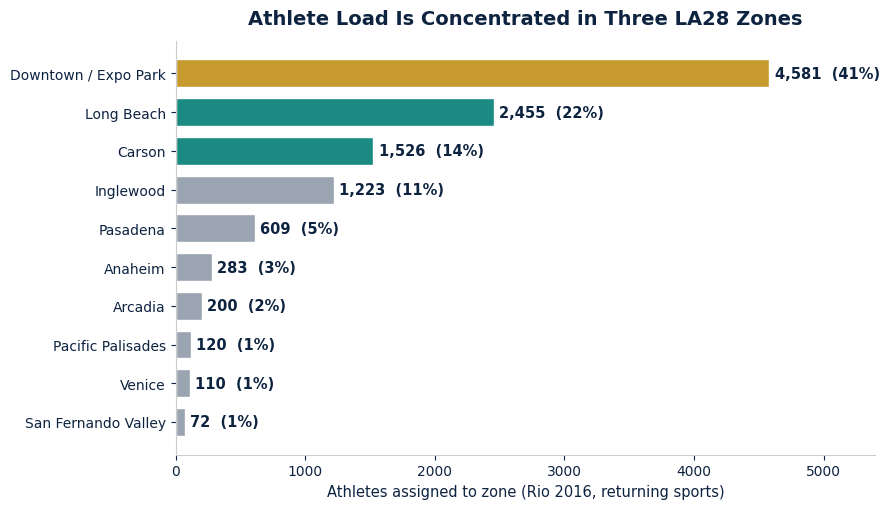

In [ ]:
NAVY, GOLD, TEAL, GREY = '#0d2340', '#c79a2e', '#1a8a82', '#9aa5b1'

zl = zone_load.sort_values()                    # ascending for horizontal bars
labels = [z.replace('Downtown/Exposition Park', 'Downtown / Expo Park')
          for z in zl.index]
ranked = zone_load.index.tolist()               # descending rank
colors = [GOLD if ranked.index(z) < 1
          else TEAL if ranked.index(z) < 3
          else GREY for z in zl.index]

fig, ax = plt.subplots(figsize=(9, 5.2))
bars = ax.barh(labels, zl.values, color=colors, edgecolor='white', height=0.72)
for b, v in zip(bars, zl.values):
    ax.text(v + 40, b.get_y() + b.get_height()/2,
            f"{v:,}  ({v/total*100:.0f}%)",
            va='center', ha='left', fontsize=10.5, color=NAVY, fontweight='bold')

ax.set_xlim(0, 5400)
ax.set_xlabel('Athletes assigned to zone (Rio 2016, returning sports)',
              fontsize=10.5, color=NAVY)
ax.set_title('Athlete Load Is Concentrated in Three LA28 Zones',
             fontsize=14, fontweight='bold', color=NAVY, pad=12)
ax.spines[['top', 'right']].set_visible(False)
ax.spines[['left', 'bottom']].set_color('#cccccc')
ax.tick_params(colors=NAVY, labelsize=10)
plt.tight_layout()
plt.savefig('chart1_zone_load.png', dpi=150, bbox_inches='tight')
plt.show()

## 9 · Chart 2 — Stability across Games (Q&A defense visual)

Grouped bars showing the four largest zones' shares across 2008/2012/2016 —
the visual proof that the concentration is structural.

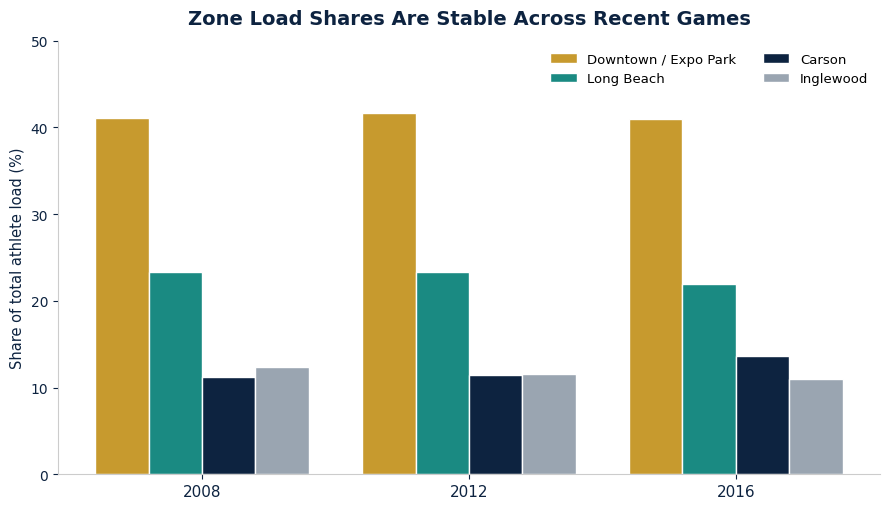

In [ ]:
years = [2008, 2012, 2016]
zones_track = ['Downtown/Exposition Park', 'Long Beach', 'Carson', 'Inglewood']
zcolors = {'Downtown/Exposition Park': GOLD, 'Long Beach': TEAL,
           'Carson': NAVY, 'Inglewood': GREY}

shares = {yr: zone_shares(yr) for yr in years}
x = np.arange(len(years)); w = 0.2

fig, ax = plt.subplots(figsize=(9, 5.2))
for i, z in enumerate(zones_track):
    vals = [shares[yr].get(z, 0) for yr in years]
    lbl = z.replace('Downtown/Exposition Park', 'Downtown / Expo Park')
    ax.bar(x + (i - 1.5)*w, vals, w, label=lbl,
           color=zcolors[z], edgecolor='white')

ax.set_xticks(x); ax.set_xticklabels(years, fontsize=11, color=NAVY)
ax.set_ylabel('Share of total athlete load (%)', fontsize=10.5, color=NAVY)
ax.set_ylim(0, 50)
ax.set_title('Zone Load Shares Are Stable Across Recent Games',
             fontsize=14, fontweight='bold', color=NAVY, pad=12)
ax.legend(frameon=False, fontsize=9.5, ncol=2, loc='upper right')
ax.spines[['top', 'right']].set_visible(False)
ax.spines[['left', 'bottom']].set_color('#cccccc')
ax.tick_params(colors=NAVY)
plt.tight_layout()
plt.savefig('chart2_robustness.png', dpi=150, bbox_inches='tight')
plt.show()

## 10 · Recommendation that follows from the data

**Finding.** Under LA28's distributed venue model, athlete load is sharply uneven:
three zones (Downtown/Exposition Park, Long Beach, Carson) carry ~77% of all
athletes, and this split is stable across the last three Games. The heaviest zone
is also internally stacked (Coliseum + Convention Center).

**Recommendation — a zone-weighted resource allocation model.** SportsFanatics
should advise LAOCOG to pre-position operational resources in proportion to each
zone's **Load Index** rather than uniformly or by venue prestige:

| Lever | Where the data says to concentrate it |
|---|---|
| Athlete-shuttle frequency & dedicated transit lanes | Downtown (100), Long Beach (54), Carson (33) first |
| Medical / recovery capacity | Scaled to zone load index, not venue seating |
| Security & crowd-management staffing | Weighted to the three high-load zones; special attention to the Downtown Coliseum + Convention Center stack |
| Housing / village shuttle routing | Prioritize fast links to the three zones that move ~8 of every 10 athletes |

**Necessary resources:** zone-level transport scheduling teams, a load-indexed
staffing model, and venue-cluster medical provisioning — all reallocations of
existing Games budget, not new spend.

**Feasibility.** Every weight traces to historical athlete data joined to LA28's
own published venue plan; the allocation is a planning input LAOCOG can act on
directly, and the stability result means it will not be invalidated by which
specific athletes qualify in 2028.

**Global transferability.** Any future host using a distributed, multi-zone model
can apply the same load-index method to pre-position resources before opening day.

In [ ]:
# Final deliverable table: the Zone Load Index handed to the client
deliverable = zone_summary[['athletes', 'n_sports', 'share_%', 'load_index']].copy()
deliverable.columns = ['Athletes', 'Sports', 'Share %', 'Load Index (max=100)']
print("ZONE LOAD INDEX  —  SportsFanatics deliverable for LAOCOG")
print("="*60)
deliverable

ZONE LOAD INDEX  —  SportsFanatics deliverable for LAOCOG


,Athletes,Sports,Share %,Load Index (max=100)
Zone,,,,
Downtown/Exposition Park,4581,12,41.0,100.0
Long Beach,2455,8,22.0,53.6
Carson,1526,5,13.7,33.3
Inglewood,1223,2,10.9,26.7
Pasadena,609,2,5.4,13.3
Anaheim,283,1,2.5,6.2
Arcadia,200,1,1.8,4.4
Pacific Palisades,120,1,1.1,2.6
Venice,110,1,1.0,2.4


---
*Data: Kaggle `athlete_events.csv` (1896–2016) + `noc_regions.csv`. Venue
assignments: LA28 official venue plan (March 2026 map). Reference Games: Rio 2016.
Scope: 31 returning sports; five new LA28 sports handled in the judge supplement.*